<a href="https://colab.research.google.com/github/mohammedshakir7/CRM_CW_1/blob/main/CRM_CW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q yfinance

In [ ]:
# Setup: libraries
import datetime as dt
import platform
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

In [ ]:
# Study period and retrieval date
START = "2021-01-01"
END = "2025-01-01"
RETRIEVED = dt.date.today().isoformat()

In [ ]:
# Package versions and retrieval date
print("Python:", platform.python_version())
print("pandas:", pd.__version__)
print("yfinance:", yf.__version__)
print("Retrieved on:", RETRIEVED)

Python: 3.13.18
pandas: 2.2.3
yfinance: 0.2.66
Retrieved on: 2026-11-25


# Task 1 Data Preparation and Feature Engineering

In [ ]:
# Task 1.1 - S&P 500 tickers from Wikipedia
url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
sp500_df = pd.read_html(url, storage_options={"User-Agent": "Mozilla/5.0"})[0]

sp500_df["Ticker"] = sp500_df["Symbol"].str.replace(".", "-", regex=False)
tickers = sp500_df["Ticker"].tolist()
print("Number of tickers:", len(tickers))

Number of tickers: 503


In [ ]:
# Task 1.1 - Save the constituent list with the retrieval date
sp500_df.to_csv(f"sp500_constituents_{RETRIEVED}.csv", index=False)
sp500_df[["Ticker", "Security", "GICS Sector"]].head()

,Ticker,Security,GICS Sector
0,MMM,3M,Industrials
1,AOS,A. O. Smith,Industrials
2,ABT,Abbott Laboratories,Health Care
3,ABBV,AbbVie,Health Care
4,ACN,Accenture,Information Technology


In [ ]:
# Download shares + S&P 500 index (^GSPC)
raw = yf.download(
    tickers + ["^GSPC"],
    start=START, end=END,
    auto_adjust=False, actions=True,
    group_by="column", progress=False,
)
raw.shape

ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['Q', 'HONA', 'VYLR', 'FDXF', 'SNDK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


(1005, 4022)

In [ ]:
# Separate the price, volume and split tables
adj = raw["Adj Close"]
close = raw["Close"]
vol = raw["Volume"]
splits = raw["Stock Splits"]
adj.shape

(1005, 504)

In [ ]:
# Save the daily data snapshot (Adj Close, Close, Volume)
adj.to_csv("adj_close_daily.csv")
close.to_csv("close_daily.csv")
vol.to_csv("volume_daily.csv")
print("Saved 3 files")

Saved 3 files


In [ ]:
# Task 1.2 - Duplicate date check
print("Duplicate dates:", adj.index.duplicated().sum())

Duplicate dates: 0


In [ ]:
# Task 1.2 - Benchmark trading calendar (^GSPC)
bench = adj["^GSPC"].dropna()
trading_days = bench.index
print("Benchmark trading days:", len(trading_days))
print("First / last day:", trading_days[0].date(), trading_days[-1].date())

Benchmark trading days: 1005
First / last day: 2021-01-04 2024-12-31


In [ ]:
# Validation rules - each excluded share is logged with a reason
exclusions = []
valid = []

for t in tickers:
    if t not in adj.columns or adj[t].dropna().empty:
        exclusions.append({"Share": t, "Reason": "no data downloaded"})
        continue

    a = adj[t].reindex(trading_days)
    c = close[t].reindex(trading_days)
    v = vol[t].reindex(trading_days)

    if a.isna().any() or c.isna().any() or v.isna().any():
        exclusions.append({"Share": t, "Reason": f"incomplete history (starts {a.first_valid_index().date()})"})
    elif (a <= 0).any() or (c <= 0).any():
        exclusions.append({"Share": t, "Reason": "non-positive price"})
    elif (v < 0).any():
        exclusions.append({"Share": t, "Reason": "negative volume"})
    elif (v == 0).any():
        exclusions.append({"Share": t, "Reason": f"{int((v == 0).sum())} zero-volume days"})
    else:
        valid.append(t)

In [ ]:
# Exclusion log - save and show
exclusion_log = pd.DataFrame(exclusions)
exclusion_log.to_csv("exclusion_log.csv", index=False)
print(f"Kept {len(valid)} of {len(tickers)} shares, excluded {len(exclusion_log)}")
exclusion_log

Kept 486 of 503 shares, excluded 17


,Share,Reason
0,APP,incomplete history (starts 2021-04-15)
1,COIN,incomplete history (starts 2021-04-14)
2,CEG,incomplete history (starts 2022-01-19)
3,EXE,incomplete history (starts 2021-02-10)
4,FDXF,no data downloaded
5,FERG,27 zero-volume days
6,GEHC,incomplete history (starts 2022-12-15)
7,GEV,incomplete history (starts 2024-03-27)
8,HONA,no data downloaded
9,Q,no data downloaded


In [ ]:
# Corporate actions - which kept shares had stock splits?
split_counts = (splits[valid].fillna(0) > 0).sum()
split_shares = split_counts[split_counts > 0].sort_values(ascending=False)
print("Shares with splits:", len(split_shares))
print(split_shares)

Shares with splits: 53
Ticker
GE       3
CPRT     2
ANET     2
WRB      2
APH      2
NVDA     2
PANW     2
BDX      1
T        1
AMZN     1
GOOG     1
CTAS     1
TECH     1
COO      1
CSGP     1
CSX      1
DHR      1
AVGO     1
CMG      1
MMM      1
GOOGL    1
DTE      1
DXCM     1
DELL     1
DECK     1
FTNT     1
ETR      1
FLEX     1
EXC      1
ISRG     1
J        1
LH       1
LRCX     1
MRK      1
IBM      1
ILMN     1
IP       1
NDAQ     1
MNST     1
MCHP     1
ODFL     1
RJF      1
O        1
SRE      1
PCAR     1
SHW      1
SMCI     1
TPL      1
TSLA     1
TSCO     1
WMT      1
WSM      1
ZBH      1
dtype: int64


In [ ]:
# Corporate actions - Adj Close / Close ratio (dividend adjustment check)
ratio = (adj[valid] / close[valid])
print("Adj Close / Close ratio range:", round(ratio.min().min(), 3), "to", round(ratio.max().max(), 3))

Adj Close / Close ratio range: 0.646 to 1.0


In [ ]:
# Task 1.2 - Check that Close is split-adjusted: largest daily Close change on a split date
split_days = splits[valid].fillna(0).stack()
split_days = split_days[split_days > 0]
jumps = [abs(close[t].pct_change(fill_method=None).loc[d]) for d, t in split_days.index]
print("Split events:", len(jumps), "| largest daily Close change on a split date:", round(max(jumps) * 100, 1), "%")

Split events: 61 | largest daily Close change on a split date: 7.7 %


In [ ]:
# Task 1.3.1 - Friday-ending weekly prices, complete weeks only
weekly = adj[valid + ["^GSPC"]].reindex(trading_days).resample("W-FRI").last()

week_labels = weekly.index
complete = ((week_labels - pd.Timedelta(days=6)) >= pd.Timestamp(START)) & (week_labels < pd.Timestamp(END))
weekly = weekly.loc[complete]
print("Dropped week labels:", list(week_labels[~complete].date))

Dropped week labels: [datetime.date(2025, 1, 3)]


In [ ]:
# Task 1.3.1 - Weekly returns on common week labels
weekly_returns = weekly.pct_change(fill_method=None).iloc[1:]
market_weekly = weekly_returns["^GSPC"]
share_weekly = weekly_returns[valid]

print("First / last return week:", weekly_returns.index[0].date(), weekly_returns.index[-1].date())
print("Number of weekly returns:", len(weekly_returns))

First / last return week: 2021-01-15 2024-12-27
Number of weekly returns: 207


In [ ]:
# Task 1.3.1 - Mean weekly return per share
mean_weekly_return = share_weekly.mean()
return_obs = share_weekly.notna().sum()
mean_weekly_return.describe()

,0
count,486.000000
mean,0.002857
std,0.002652
min,-0.004468
25%,0.001182
50%,0.002619
75%,0.004207
max,0.017772


In [ ]:
# Task 1.3.2 - Weekly beta function: Cov(share, market) / Var(market)
def calculate_weekly_beta(weekly_returns, market_returns, min_weeks=52):
    results = []
    for share in weekly_returns.columns:
        paired = pd.concat(
            [weekly_returns[share].rename("share"), market_returns.rename("market")],
            axis=1,
        ).replace([np.inf, -np.inf], np.nan).dropna()

        variance = paired["market"].var(ddof=1)
        beta = np.nan
        if len(paired) >= min_weeks and variance > 0:
            beta = paired["share"].cov(paired["market"]) / variance
        results.append({"Share": share, "Beta": beta, "Paired_weeks": len(paired)})
    return pd.DataFrame(results).set_index("Share")

In [ ]:
# Task 1.3.2 - Weekly beta for every kept share
beta_df = calculate_weekly_beta(share_weekly, market_weekly)
print("Paired weeks (min/max):", beta_df["Paired_weeks"].min(), beta_df["Paired_weeks"].max())
beta_df["Beta"].describe()

Paired weeks (min/max): 207 207


,Beta
count,486.000000
mean,0.973695
std,0.407339
min,0.055453
25%,0.666599
50%,0.950610
75%,1.179538
max,3.778560


In [ ]:
# Task 1.3.2 - Check: beta equals the regression slope
t0 = valid[0]
slope = np.polyfit(market_weekly, share_weekly[t0], 1)[0]
print(f"Check {t0}: beta {beta_df.loc[t0, 'Beta']:.4f} vs regression slope {slope:.4f}")

Check MMM: beta 0.8691 vs regression slope 0.8691


In [ ]:
# Highest and lowest beta shares
print(beta_df["Beta"].sort_values().head(5))
print(beta_df["Beta"].sort_values().tail(5))

Share
GIS    0.055453
SJM    0.175579
MRK    0.198285
BMY    0.225014
KHC    0.227169
Name: Beta, dtype: float64
Share
TWLO    2.073379
NVDA    2.125954
COHR    2.139305
XYZ     2.504520
CVNA    3.778560
Name: Beta, dtype: float64


In [ ]:
# Task 1.4 - Observation date and window sizes
obs_date = vol[valid].reindex(trading_days).dropna(how="any").index.max()
print("Observation date:", obs_date.date())

WINDOW = 60
BASELINE = 20

Observation date: 2024-12-31


In [ ]:
# Task 1.4 - High-volume day rule: volume > 2 x mean of previous 20 sessions
def flag_high_volume(t):
    d = pd.DataFrame({"Close": close[t], "Volume": vol[t]})
    d = d.reindex(trading_days).loc[:obs_date].dropna()
    baseline = d["Volume"].shift(1).rolling(BASELINE).mean()
    d["Threshold"] = 2 * baseline
    d["HighVolume"] = d["Volume"] > d["Threshold"]
    return d.loc[baseline.notna()]

In [ ]:
# Task 1.4 - Flag high-volume days for every kept share
flags = {t: flag_high_volume(t) for t in valid}
short = [t for t, d in flags.items() if len(d) < WINDOW]
print("Shares without enough history:", short)

Shares without enough history: []


In [ ]:
# Task 1.4.1 - Recency: calendar days since the last high-volume day
recency, last_event = {}, {}
for t, d in flags.items():
    events = d.index[d["HighVolume"]]
    if len(events):
        recency[t] = (obs_date - events[-1]).days
        last_event[t] = events[-1].date()
    else:
        recency[t] = pd.NA
        last_event[t] = None

In [ ]:
# Task 1.4.1 - Recency summary and no-event check
recency = pd.Series(recency, name="Recency").astype("Int64")
print("No high-volume event:", recency[recency.isna()].index.tolist())
recency.describe()

No high-volume event: []


,Recency
count,486.0
mean,20.407407
std,21.342438
min,4.0
25%,11.0
50%,11.0
75%,14.75
max,222.0


In [ ]:
# Task 1.4.2 - Frequency: high-volume days in the latest 60 sessions
frequency = pd.Series(
    {t: int(d.tail(WINDOW)["HighVolume"].sum()) for t, d in flags.items()},
    name="Frequency",
)
frequency.value_counts().sort_index()

,count
Frequency,
0,10
1,42
2,130
3,149
4,94
5,45
6,11
7,3
8,2


In [ ]:
# Task 1.4.3 - Monetary: sum of Close x Volume over the latest 60 sessions (USD)
monetary = pd.Series(
    {t: float((d.tail(WINDOW)["Close"] * d.tail(WINDOW)["Volume"]).sum()) for t, d in flags.items()},
    name="Monetary",
)
(monetary / 1e9).describe().round(2)

,Monetary
count,486.00
mean,39.40
std,129.14
min,1.30
25%,10.20
50%,16.68
75%,32.28
max,1847.70


In [ ]:
# Combine R, F and M into one table
rfm = pd.concat([recency, frequency, monetary], axis=1)
rfm["LastEvent"] = pd.Series(last_event)
rfm["WindowStart"] = {t: d.tail(WINDOW).index[0].date() for t, d in flags.items()}
print("Shares with RFM:", len(rfm))
rfm.head()

Shares with RFM: 486


,Recency,Frequency,Monetary,LastEvent,WindowStart
MMM,11,4,2.599146e+10,2024-12-20,2024-10-07
AOS,11,2,4.748980e+09,2024-12-20,2024-10-07
ABT,11,1,3.523027e+10,2024-12-20,2024-10-07
ABBV,11,3,6.837054e+10,2024-12-20,2024-10-07
ACN,11,2,5.199430e+10,2024-12-20,2024-10-07


In [ ]:
# 1.5 - Feature table (one row per share) saved to CSV
features = pd.DataFrame({"MeanWeeklyReturn": mean_weekly_return, "WeeklyObs": return_obs})
features = features.join(beta_df).join(rfm)
features = features.join(sp500_df.set_index("Ticker")[["Security", "GICS Sector"]])
features["ObservationDate"] = obs_date.date()
features.to_csv("task1_feature_table.csv")

In [ ]:
# 1.5 - Feature summaries
cols = ["MeanWeeklyReturn", "Beta", "Recency", "Frequency", "Monetary"]
features[cols].describe().round(4)

,MeanWeeklyReturn,Beta,Recency,Frequency,Monetary
count,486.0000,486.0000,486.0,486.0000,4.860000e+02
mean,0.0029,0.9737,20.4074,2.9897,3.940419e+10
std,0.0027,0.4073,21.3424,1.3308,1.291388e+11
min,-0.0045,0.0555,4.0,0.0000,1.297483e+09
25%,0.0012,0.6666,11.0,2.0000,1.019517e+10
50%,0.0026,0.9506,11.0,3.0000,1.668382e+10
75%,0.0042,1.1795,14.75,4.0000,3.227689e+10
max,0.0178,3.7786,222.0,8.0000,1.847697e+12


In [ ]:
# 1.5 - Inclusion and exclusion log
print("Shares in Wikipedia list:", len(tickers))
print("Shares included:", len(features))
exclusion_log["Reason"].str.split(" \\(").str[0].value_counts()

Shares in Wikipedia list: 503
Shares included: 486


,count
Reason,
incomplete history,10
no data downloaded,5
27 zero-volume days,1
424 zero-volume days,1


In [ ]:
# 1.5 - Worked RFM example (MMM): R, F and M step by step
EX = "MMM"
d = flags[EX]
window = d.tail(WINDOW)
last = d.index[d["HighVolume"]][-1]
prev20 = d["Volume"].loc[:last].iloc[-21:-1]

print("Window:", window.index[0].date(), "to", window.index[-1].date())
print("Last event:", last.date(), "| volume:", int(d.loc[last, "Volume"]), "| threshold:", round(2 * prev20.mean()))
print("Recency:", (obs_date - last).days, "days")
print("Frequency:", int(window["HighVolume"].sum()), "days")
print("Monetary: $", round((window["Close"] * window["Volume"]).sum() / 1e9, 2), "bn")

Window: 2024-10-07 to 2024-12-31
Last event: 2024-12-20 | volume: 8351300 | threshold: 6055080
Recency: 11 days
Frequency: 4 days
Monetary: $ 25.99 bn


In [ ]:
# 1.5 - Worked example: MMM's high-volume days in the 60-session window
window.loc[window["HighVolume"], ["Volume", "Threshold"]]

,Volume,Threshold
Date,,
2024-10-21,5940600,5659850.0
2024-10-22,13082300,5990070.0
2024-10-23,8116200,6983770.0
2024-12-20,8351300,6055080.0


In [ ]:
# 1.5 - Checks: threshold alignment and no-event handling
ok = all(np.isclose(flags[t]["Threshold"].iloc[-1], 2 * flags[t]["Volume"].iloc[-21:-1].mean()) for t in valid[:20])
print("Threshold uses previous 20 sessions only:", ok)
print("Shares with no event:", features["Recency"].isna().sum())

Threshold uses previous 20 sessions only: True
Shares with no event: 0


In [ ]:
# 1.5 - Checks: enough history for the 20-session baseline and 60-session window
print("Fewest sessions before 60-session window:", min(len(flags[t]) - WINDOW for t in valid))
print("All windows 60 sessions ending", obs_date.date(), ":",
      all(len(flags[t].tail(WINDOW)) == 60 and flags[t].index[-1] == obs_date for t in valid))

Fewest sessions before 60-session window: 925
All windows 60 sessions ending 2024-12-31 : True


In [ ]:
# 1.5 - Common valid share set for Task 2
common = features.dropna(subset=cols).index
pd.Series(common, name="Share").to_csv("common_share_set.csv", index=False)
print("Common valid share set:", len(common))

Common valid share set: 486


In [ ]:
# 1.5 - Brief's worked examples reproduced
print("Brief Recency example (20 Sep - 15 Sep):", (pd.Timestamp("2024-09-20") - pd.Timestamp("2024-09-15")).days)
print("Brief Frequency example (2.5m > 2 x 1.0m):", 2_500_000 > 2 * 1_000_000, "| (1.8m):", 1_800_000 > 2 * 1_000_000)
print("Brief Monetary example ($100 x 2m):", 100 * 2_000_000)

Brief Recency example (20 Sep - 15 Sep): 5
Brief Frequency example (2.5m > 2 x 1.0m): True | (1.8m): False
Brief Monetary example ($100 x 2m): 200000000


In [ ]:
# 1.5 - Threshold check on 500 random share-days
rng = np.random.default_rng(42)
checks = []
for _ in range(500):
    t = rng.choice(valid)
    d = flags[t]
    i = rng.integers(20, len(d))
    expected = 2 * vol[t].reindex(trading_days).loc[:d.index[i]].iloc[-21:-1].mean()
    checks.append(np.isclose(d["Threshold"].iloc[i], expected))
print("Random share-day threshold checks passed:", sum(checks), "of", len(checks))

Random share-day threshold checks passed: 500 of 500


# Task 2 Stock Segmentation and Sensitivity Analysis

In [ ]:
# Task 2.1 - Two feature matrices on the common share set
X_rr = features.loc[common, ["MeanWeeklyReturn", "Beta"]].copy()
X_rfm = features.loc[common, ["Recency", "Frequency", "Monetary"]].astype(float).copy()
X_rfm["Monetary"] = np.log1p(X_rfm["Monetary"])
print("Risk-return matrix:", X_rr.shape, "| RFM matrix:", X_rfm.shape)

Risk-return matrix: (486, 2) | RFM matrix: (486, 3)


In [ ]:
# Task 2.1 - Raw and prepared features, and the outlier rule (|z| > 3)
raw_feat = features.loc[common, cols].astype(float)
prepared = pd.concat([X_rr, X_rfm], axis=1).rename(columns={"Monetary": "log1p(Monetary)"})

def outliers(df):
    z = (df - df.mean()) / df.std()
    return (z.abs() > 3).sum()

In [ ]:
# Task 2.1 - Skew and outlier diagnostics
diag = pd.DataFrame({
    "Skew (raw)": raw_feat.skew().values,
    "Skew (prepared)": prepared.skew().values,
    "Outliers |z|>3 (raw)": outliers(raw_feat).values,
    "Outliers |z|>3 (prepared)": outliers(prepared).values,
}, index=cols).round(2)
diag

,Skew (raw),Skew (prepared),Outliers |z|>3 (raw),Outliers |z|>3 (prepared)
MeanWeeklyReturn,0.87,0.87,6,6
Beta,1.10,1.10,2,2
Recency,3.65,3.65,11,11
Frequency,0.42,0.42,5,5
Monetary,11.68,1.08,5,7


In [ ]:
# Task 2.1 - Standardise each matrix separately
from sklearn.preprocessing import StandardScaler

Z_rr = pd.DataFrame(StandardScaler().fit_transform(X_rr), index=X_rr.index, columns=X_rr.columns)
Z_rfm = pd.DataFrame(StandardScaler().fit_transform(X_rfm), index=X_rfm.index, columns=X_rfm.columns)
pd.concat([Z_rr, Z_rfm], axis=1).agg(["mean", "std"]).round(2)

,MeanWeeklyReturn,Beta,Recency,Frequency,Monetary
mean,0.0,-0.0,-0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0


In [ ]:
# Task 2.1 - Other skewed variables: skew before and after log1p
rfm_raw = features.loc[common, ["Recency", "Frequency", "Monetary"]].astype(float)
pd.DataFrame({"Skew raw": rfm_raw.skew(), "Skew if log1p": np.log1p(rfm_raw).skew()}).round(2)

,Skew raw,Skew if log1p
Recency,3.65,1.58
Frequency,0.42,-0.93
Monetary,11.68,1.08


In [ ]:
# Task 2.1 - Shares that are outliers (|z| > 3) after preparation
zp = (prepared - prepared.mean()) / prepared.std()
flagged = zp.index[(zp.abs() > 3).any(axis=1)]
print("Shares with |z| > 3 after preparation:", len(flagged))
features.loc[flagged, ["Security", "GICS Sector", "Beta", "Recency", "Monetary"]].sort_values("Beta", ascending=False)

Shares with |z| > 3 after preparation: 28


,Security,GICS Sector,Beta,Recency,Monetary
Ticker,,,,,
CVNA,Carvana,Consumer Discretionary,3.778560,36,3.836519e+10
XYZ,"Block, Inc.",Financials,2.504520,49,4.052406e+10
NVDA,Nvidia,Information Technology,2.125954,222,1.825337e+12
TSLA,"Tesla, Inc.",Consumer Discretionary,2.045761,50,1.847697e+12
VRT,Vertiv,Industrials,2.001479,42,4.685913e+10
SMCI,Supermicro,Information Technology,1.783662,29,1.676740e+11
AVGO,Broadcom,Information Technology,1.515254,11,3.340388e+11
FCX,Freeport-McMoRan,Materials,1.492186,96,2.847770e+10
AMZN,Amazon,Consumer Discretionary,1.386667,11,4.681770e+11


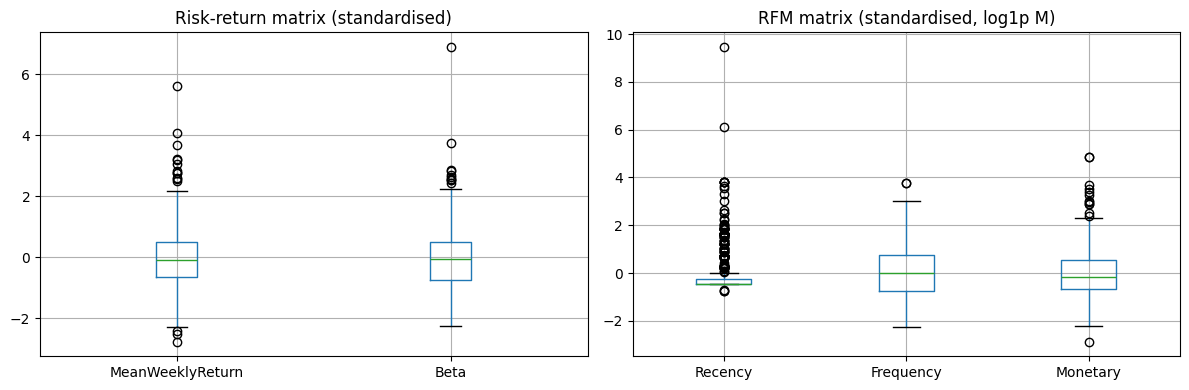

In [ ]:
# Task 2.1 - Standardised features (boxplot shows remaining outliers)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
Z_rr.boxplot(ax=ax[0]); ax[0].set_title("Risk-return matrix (standardised)")
Z_rfm.boxplot(ax=ax[1]); ax[1].set_title("RFM matrix (standardised, log1p M)")
plt.tight_layout(); plt.savefig("task2_standardised_boxplots.png", dpi=150); plt.show()

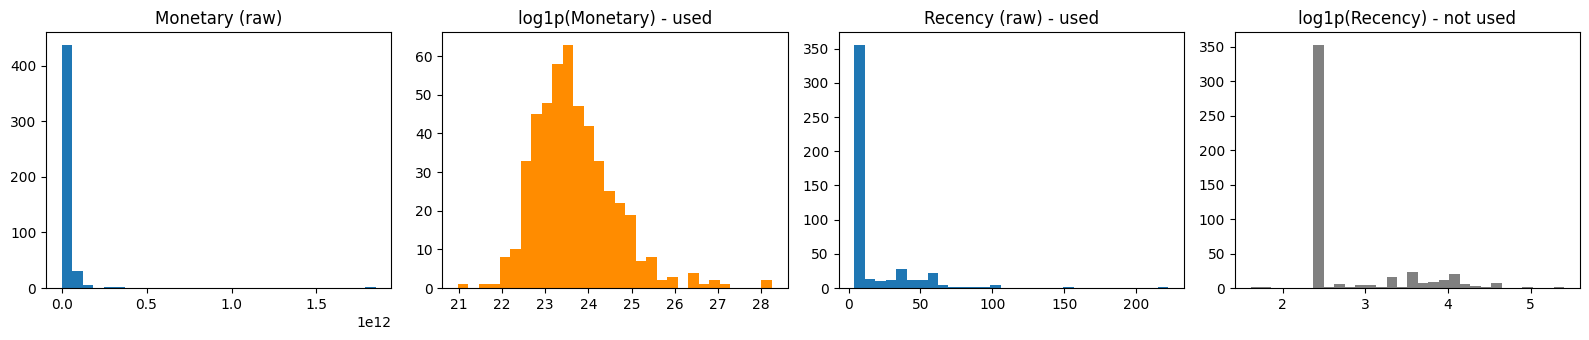

In [ ]:
# Task 2.1 - Effect of log1p on the skewed RFM features
fig, ax = plt.subplots(1, 4, figsize=(16, 3.5))
ax[0].hist(rfm_raw["Monetary"], bins=30); ax[0].set_title("Monetary (raw)")
ax[1].hist(np.log1p(rfm_raw["Monetary"]), bins=30, color="darkorange"); ax[1].set_title("log1p(Monetary) - used")
ax[2].hist(rfm_raw["Recency"], bins=30); ax[2].set_title("Recency (raw) - used")
ax[3].hist(np.log1p(rfm_raw["Recency"]), bins=30, color="grey"); ax[3].set_title("log1p(Recency) - not used")
plt.tight_layout(); plt.savefig("task2_log1p_effect.png", dpi=150); plt.show()

In [ ]:
# Task 2.2 - Ward linkage (Euclidean) on each standardised matrix
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

L_rr = linkage(Z_rr.values, method="ward", metric="euclidean")
L_rfm = linkage(Z_rfm.values, method="ward", metric="euclidean")

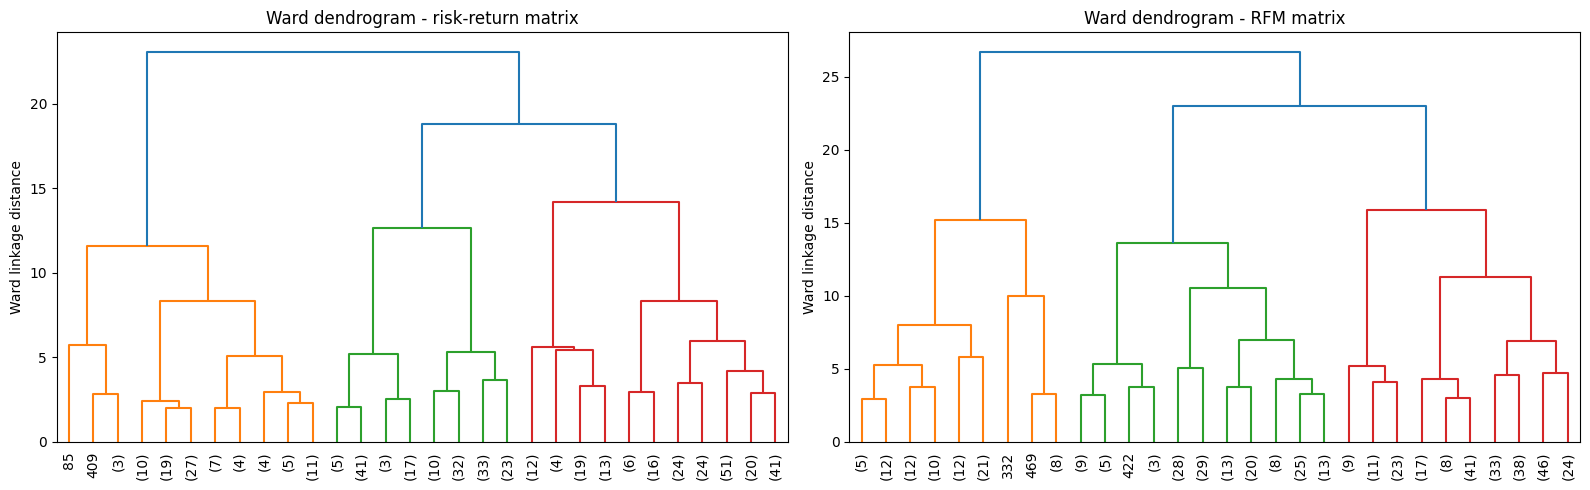

In [ ]:
# Task 2.2 - One dendrogram per matrix (last 30 merges shown)
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
dendrogram(L_rr, ax=ax[0], truncate_mode="lastp", p=30, leaf_rotation=90)
ax[0].set_title("Ward dendrogram - risk-return matrix")
ax[0].set_ylabel("Ward linkage distance")
dendrogram(L_rfm, ax=ax[1], truncate_mode="lastp", p=30, leaf_rotation=90)
ax[1].set_title("Ward dendrogram - RFM matrix")
ax[1].set_ylabel("Ward linkage distance")
plt.tight_layout()
plt.savefig("task2_ward_dendrograms.png", dpi=150)
plt.show()

In [ ]:
# Task 2.2 - Last 8 merge heights (big jumps suggest where to cut)
print("Last 8 merge heights (risk-return):", L_rr[-8:, 2].round(2))
print("Last 8 merge heights (RFM):        ", L_rfm[-8:, 2].round(2))

Last 8 merge heights (risk-return): [ 5.93  8.31  8.34 11.6  12.67 14.21 18.8  23.07]
Last 8 merge heights (RFM):         [ 9.97 10.54 11.29 13.58 15.15 15.84 22.99 26.71]


In [ ]:
# Task 2.2 - Compare k = 2 to 8: silhouette and cluster sizes
from sklearn.metrics import silhouette_score

rows = []
for name, Z, L in [("Risk-return", Z_rr, L_rr), ("RFM", Z_rfm, L_rfm)]:
    for k in range(2, 9):
        ward_labels = fcluster(L, k, criterion="maxclust")
        sizes = sorted(np.bincount(ward_labels)[1:], reverse=True)
        rows.append({"Matrix": name, "k": k,
                     "Silhouette": round(silhouette_score(Z, ward_labels), 3),
                     "Smallest cluster": min(sizes), "Sizes": sizes})
ward_k = pd.DataFrame(rows)
ward_k

,Matrix,k,Silhouette,Smallest cluster,Sizes
0,Risk-return,2,0.339,92,"[394, 92]"
1,Risk-return,3,0.274,92,"[230, 164, 92]"
2,Risk-return,4,0.282,48,"[182, 164, 92, 48]"
3,Risk-return,5,0.304,48,"[182, 98, 92, 66, 48]"
4,Risk-return,6,0.320,5,"[182, 98, 87, 66, 48, 5]"
5,Risk-return,7,0.324,5,"[160, 98, 87, 66, 48, 22, 5]"
6,Risk-return,8,0.321,5,"[160, 98, 66, 56, 48, 31, 22, 5]"
7,RFM,2,0.368,82,"[404, 82]"
8,RFM,3,0.304,82,"[250, 154, 82]"
9,RFM,4,0.289,43,"[207, 154, 82, 43]"


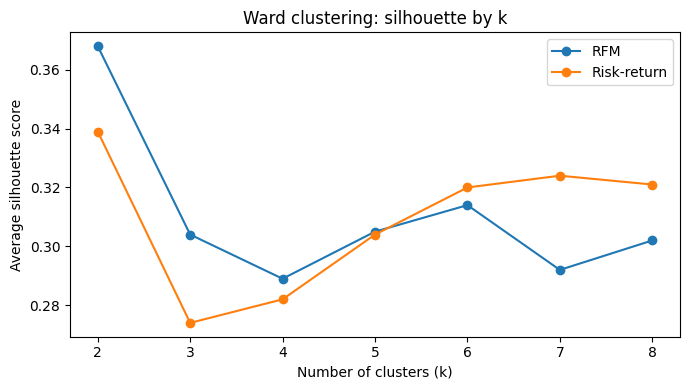

In [ ]:
# Task 2.2 - Silhouette score by k for both matrices
fig, ax = plt.subplots(figsize=(7, 4))
for name, g in ward_k.groupby("Matrix"):
    ax.plot(g["k"], g["Silhouette"], marker="o", label=name)
ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Average silhouette score")
ax.set_title("Ward clustering: silhouette by k")
ax.legend()
plt.tight_layout()
plt.savefig("task2_ward_silhouette.png", dpi=150)
plt.show()

In [ ]:
# Task 2.2 - Profile function: cluster medians in original units
def profile(L, cols_, k):
    df = features.loc[common, cols_].astype(float).copy()
    if "Monetary" in df:
        df["Monetary"] = df["Monetary"] / 1e9
    df["Cluster"] = fcluster(L, k, criterion="maxclust")
    out = df.groupby("Cluster").median().round(4)
    out.insert(0, "Shares", df["Cluster"].value_counts().sort_index())
    return out

In [ ]:
# Task 2.2 - Risk-return profiles for shortlisted k (2, 3, 5)
for k in [2, 3, 5]:
    print(f"\nRisk-return - Ward k={k} (medians)")
    display(profile(L_rr, ["MeanWeeklyReturn", "Beta"], k))


Risk-return - Ward k=2 (medians)


,Shares,MeanWeeklyReturn,Beta
Cluster,,,
1,92,0.0055,1.2177
2,394,0.0021,0.8817



Risk-return - Ward k=3 (medians)


,Shares,MeanWeeklyReturn,Beta
Cluster,,,
1,92,0.0055,1.2177
2,164,0.0033,0.5777
3,230,0.0017,1.0384



Risk-return - Ward k=5 (medians)


,Shares,MeanWeeklyReturn,Beta
Cluster,,,
1,92,0.0055,1.2177
2,66,0.0011,0.4485
3,98,0.0039,0.6663
4,48,0.0025,1.5139
5,182,0.0017,0.9644


In [ ]:
# Task 2.2 - RFM profiles for shortlisted k (2, 3, 6)
for k in [2, 3, 6]:
    print(f"\nRFM - Ward k={k} (medians, Monetary in $bn)")
    display(profile(L_rfm, ["Recency", "Frequency", "Monetary"], k))


RFM - Ward k=2 (medians, Monetary in $bn)


,Shares,Recency,Frequency,Monetary
Cluster,,,,
1,82,54.5,2.0,17.8490
2,404,11.0,3.0,16.0473



RFM - Ward k=3 (medians, Monetary in $bn)


,Shares,Recency,Frequency,Monetary
Cluster,,,,
1,82,54.5,2.0,17.8490
2,154,11.0,3.0,39.6955
3,250,11.0,3.0,11.1776



RFM - Ward k=6 (medians, Monetary in $bn)


,Shares,Recency,Frequency,Monetary
Cluster,,,,
1,72,53.0,2.0,17.6823
2,10,102.0,0.0,23.7859
3,18,12.5,5.0,244.8680
4,136,11.0,3.0,36.2982
5,43,11.0,5.0,14.4300
6,207,11.0,3.0,10.7853


In [ ]:
# Task 2.2 - Final Ward solutions (risk-return k=5, RFM k=3) saved to CSV
K_WARD_RR, K_WARD_RFM = 5, 3
ward_rr = pd.Series(fcluster(L_rr, K_WARD_RR, criterion="maxclust"), index=Z_rr.index, name="Ward_RR")
ward_rfm = pd.Series(fcluster(L_rfm, K_WARD_RFM, criterion="maxclust"), index=Z_rfm.index, name="Ward_RFM")
pd.concat([ward_rr, ward_rfm], axis=1).to_csv("task2_ward_assignments.csv")

In [ ]:
# Task 2.2 - Example shares per Ward cluster (largest traded value first)
for name, lab in [("Ward risk-return", ward_rr), ("Ward RFM", ward_rfm)]:
    print(f"\n{name} - example shares per cluster (largest traded value first)")
    for c in sorted(lab.unique()):
        members = features.loc[lab.index[lab == c]].sort_values("Monetary", ascending=False)
        print(f"  Cluster {c} ({len(members)} shares):", ", ".join(members.index[:6]))


Ward risk-return - example shares per cluster (largest traded value first)
  Cluster 1 (92 shares): NVDA, AAPL, MSFT, META, AVGO, GOOGL
  Cluster 2 (66 shares): UNH, PFE, PG, JNJ, MRK, KO
  Cluster 3 (98 shares): JPM, BRK-B, COST, XOM, WMT, CVX
  Cluster 4 (48 shares): TSLA, AMZN, AMD, MU, CRM, ADBE
  Cluster 5 (182 shares): BA, V, INTC, BAC, HD, MA

Ward RFM - example shares per cluster (largest traded value first)
  Cluster 1 (82 shares): NVDA, NFLX, NOW, TXN, INTU, TMO
  Cluster 2 (154 shares): TSLA, AAPL, MSFT, AMZN, META, AVGO
  Cluster 3 (250 shares): CI, AJG, CNC, HSY, EOG, LEN


In [ ]:
# Task 2.3 - K-means setup: fixed random seed for reproducibility
from sklearn.cluster import KMeans
SEED = 42

In [ ]:
# Task 2.3 - K-means for k = 2 to 8 on both matrices (10 initialisations each)
rows = []
for name, Z in [("Risk-return", Z_rr), ("RFM", Z_rfm)]:
    for k in range(2, 9):
        km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z)
        sizes = sorted(np.bincount(km.labels_), reverse=True)
        rows.append({"Matrix": name, "k": k,
                     "Inertia": round(km.inertia_, 1),
                     "Silhouette": round(silhouette_score(Z, km.labels_), 3),
                     "Smallest cluster": min(sizes), "Sizes": sizes})

km_k = pd.DataFrame(rows)
km_k

,Matrix,k,Inertia,Silhouette,Smallest cluster,Sizes
0,Risk-return,2,621.6,0.387,143,"[343, 143]"
1,Risk-return,3,461.2,0.329,120,"[202, 164, 120]"
2,Risk-return,4,371.6,0.327,40,"[160, 154, 132, 40]"
3,Risk-return,5,309.6,0.341,27,"[166, 131, 112, 50, 27]"
4,Risk-return,6,265.7,0.326,20,"[134, 115, 85, 76, 56, 20]"
5,Risk-return,7,227.5,0.331,5,"[143, 85, 83, 74, 48, 48, 5]"
6,Risk-return,8,196.0,0.353,5,"[143, 82, 81, 77, 36, 34, 28, 5]"
7,RFM,2,1066.8,0.423,68,"[418, 68]"
8,RFM,3,796.7,0.325,63,"[272, 151, 63]"
9,RFM,4,609.8,0.341,61,"[211, 122, 92, 61]"


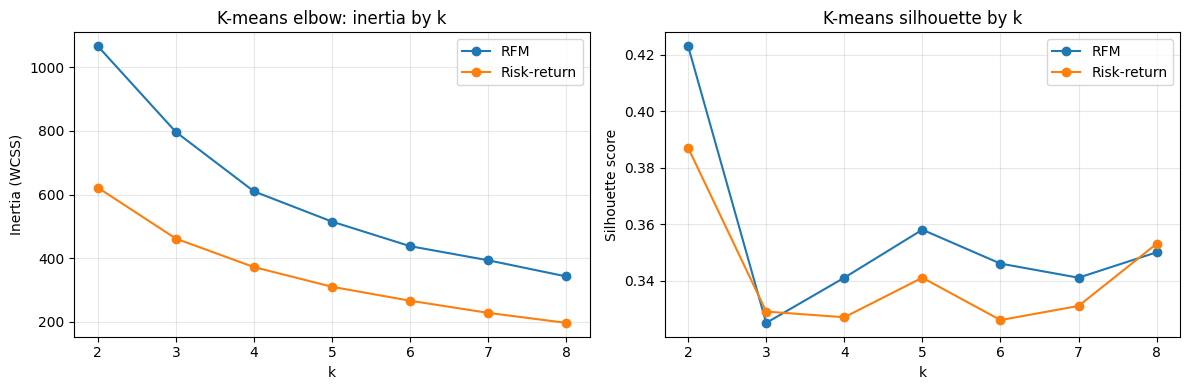

In [ ]:
# Task 2.3 - Elbow (inertia) and silhouette charts for both matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, g in km_k.groupby("Matrix"):
    axes[0].plot(g["k"], g["Inertia"], marker="o", label=name)
    axes[1].plot(g["k"], g["Silhouette"], marker="o", label=name)
axes[0].set(title="K-means elbow: inertia by k", xlabel="k", ylabel="Inertia (WCSS)")
axes[1].set(title="K-means silhouette by k", xlabel="k", ylabel="Silhouette score")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("task2_kmeans_k_selection.png", dpi=150)
plt.show()

In [ ]:
# Task 2.3 - K-means profile function: cluster medians in original units
def km_profile(Z, cols_, k):
    df = features.loc[common, cols_].astype(float).copy()
    if "Monetary" in df:
        df["Monetary"] = df["Monetary"] / 1e9
    df["Cluster"] = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z).labels_ + 1
    out = df.groupby("Cluster").median().round(4)
    out.insert(0, "Shares", df["Cluster"].value_counts().sort_index())
    return out

In [ ]:
# Task 2.3 - Risk-return K-means profiles for shortlisted k (4, 5)
for k in [4, 5]:
    print(f"\nRisk-return K-means, k = {k}")
    display(km_profile(Z_rr, ["MeanWeeklyReturn", "Beta"], k))


Risk-return K-means, k = 4


,Shares,MeanWeeklyReturn,Beta
Cluster,,,
1,132,0.0011,1.1418
2,154,0.0019,0.5767
3,40,0.0070,1.6809
4,160,0.0043,0.9851



Risk-return K-means, k = 5


,Shares,MeanWeeklyReturn,Beta
Cluster,,,
1,112,0.0007,1.0317
2,166,0.0042,0.9964
3,131,0.0020,0.5304
4,27,0.0083,1.4497
5,50,0.0027,1.5430


In [ ]:
# Task 2.3 - RFM K-means profiles for shortlisted k (3, 4, 5)
for k in [3, 4, 5]:
    print(f"\nRFM K-means, k = {k} (Monetary in $bn)")
    display(km_profile(Z_rfm, ["Recency", "Frequency", "Monetary"], k))


RFM K-means, k = 3 (Monetary in $bn)


,Shares,Recency,Frequency,Monetary
Cluster,,,,
1,272,11.0,3.0,11.4425
2,63,55.0,2.0,21.2421
3,151,11.0,3.0,42.0131



RFM K-means, k = 4 (Monetary in $bn)


,Shares,Recency,Frequency,Monetary
Cluster,,,,
1,122,11.0,4.0,12.8259
2,92,11.0,3.0,58.7561
3,61,55.0,2.0,21.2421
4,211,11.0,2.0,13.3296



RFM K-means, k = 5 (Monetary in $bn)


,Shares,Recency,Frequency,Monetary
Cluster,,,,
1,68,53.5,2.0,19.5452
2,122,11.0,4.0,12.8259
3,87,11.0,3.0,63.1016
4,11,102.0,0.0,24.8239
5,198,11.0,2.0,13.2078


In [ ]:
# Task 2.3 - Final K-means solutions (risk-return k=5, RFM k=5) saved to CSV
K_KM_RR, K_KM_RFM = 5, 5
km_rr_model = KMeans(n_clusters=K_KM_RR, n_init=10, random_state=SEED).fit(Z_rr)
km_rfm_model = KMeans(n_clusters=K_KM_RFM, n_init=10, random_state=SEED).fit(Z_rfm)
km_rr = pd.Series(km_rr_model.labels_ + 1, index=Z_rr.index, name="KM_RR")
km_rfm = pd.Series(km_rfm_model.labels_ + 1, index=Z_rfm.index, name="KM_RFM")
pd.concat([km_rr, km_rfm], axis=1).to_csv("task2_kmeans_assignments.csv")

In [ ]:
# Task 2.3 - Example shares per K-means cluster (largest traded value first)
order = features.loc[common, "Monetary"].sort_values(ascending=False).index
for name, s in [("Risk-return", km_rr), ("RFM", km_rfm)]:
    print(f"\n{name} K-means - example shares per cluster")
    s = s.reindex(order)
    for c in sorted(s.unique()):
        print(f"  Cluster {c} ({(s == c).sum()} shares):", ", ".join(s[s == c].index[:6]))


Risk-return K-means - example shares per cluster
  Cluster 1 (112 shares): BA, INTC, TXN, DIS, HON, TMO
  Cluster 2 (166 shares): AAPL, MSFT, META, GOOGL, GOOG, LLY
  Cluster 3 (131 shares): UNH, BRK-B, WMT, CVX, PFE, PG
  Cluster 4 (27 shares): NVDA, AVGO, PLTR, SMCI, MRVL, DELL
  Cluster 5 (50 shares): TSLA, AMZN, AMD, NFLX, MU, CRM

RFM K-means - example shares per cluster
  Cluster 1 (68 shares): NFLX, NOW, TXN, INTU, TMO, VST
  Cluster 2 (122 shares): HON, CVS, XYZ, MPWR, CI, BX
  Cluster 3 (87 shares): TSLA, AAPL, MSFT, AMZN, META, AVGO
  Cluster 4 (11 shares): NVDA, MDT, FCX, APD, CB, AZO
  Cluster 5 (198 shares): LOW, SPGI, TJX, GILD, ABT, FISV


In [ ]:
# Task 2.3 - Initialisation check: 20 single-start runs vs n_init=10
rows = []
for name, Z, k, model in [("Risk-return", Z_rr, K_KM_RR, km_rr_model),
                          ("RFM", Z_rfm, K_KM_RFM, km_rfm_model)]:
    single = [KMeans(n_clusters=k, n_init=1, random_state=s).fit(Z).inertia_ for s in range(20)]
    rows.append({"Matrix": name, "k": k,
                 "Inertia (n_init=10)": round(model.inertia_, 1),
                 "Best single run": round(min(single), 1),
                 "Worst single run": round(max(single), 1),
                 "Single runs worse (of 20)": sum(i > model.inertia_ + 0.01 for i in single)})
pd.DataFrame(rows)

,Matrix,k,Inertia (n_init=10),Best single run,Worst single run,Single runs worse (of 20)
0,Risk-return,5,309.6,309.8,344.2,20
1,RFM,5,514.7,514.7,654.0,16


In [ ]:
# Task 2.4 - Cluster labels for Ward and K-means (named from the profiles)
labels = {
    "Ward_RR": {1: "High return, above-market beta", 2: "Defensive, low return",
                3: "Low beta, steady return", 4: "High beta", 5: "Market-like core"},
    "KM_RR": {1: "Market beta, weak return", 2: "Market beta, strong return",
              3: "Defensive, low beta", 4: "High-beta winners", 5: "High-beta laggards"},
    "Ward_RFM": {1: "No recent spike", 2: "Recent spike, high traded value",
                 3: "Recent spike, lower traded value"},
    "KM_RFM": {1: "No recent spike", 2: "Frequent recent spikers", 3: "Very heavily traded",
               4: "Dormant (no spike in window)", 5: "Core, recent spike"},
}

In [ ]:
# Task 2.4 - All four cluster assignments in one table
assign = pd.concat([ward_rr, ward_rfm, km_rr, km_rfm], axis=1)
rr_cols = ["MeanWeeklyReturn", "Beta"]
rfm_cols = ["Recency", "Frequency", "Monetary"]
assign.head()

,Ward_RR,Ward_RFM,KM_RR,KM_RFM
Ticker,,,,
MMM,5,2,1,2
AOS,5,3,1,5
ABT,2,2,3,5
ABBV,3,2,3,3
ACN,5,2,2,3


In [ ]:
# Task 2.4 - Profile function: medians per cluster in original units
def profile_table(col, cols_):
    df = features.loc[assign.index, cols_].astype(float).copy()
    if "MeanWeeklyReturn" in df:
        df["MeanWeeklyReturn"] *= 100
    if "Monetary" in df:
        df["Monetary"] /= 1e9
    df["Cluster"] = assign[col]
    out = df.groupby("Cluster").median().round(2)
    out.insert(0, "Shares", df["Cluster"].value_counts().sort_index())
    out.insert(0, "Label", out.index.map(labels[col]))
    return out

In [ ]:
# Task 2.4 - Profiles in original units for all four solutions (saved to CSV)
tables = {}
for col, cols_, units in [("Ward_RR", rr_cols, "weekly return in %"),
                          ("KM_RR", rr_cols, "weekly return in %"),
                          ("Ward_RFM", rfm_cols, "R in days, M in $bn"),
                          ("KM_RFM", rfm_cols, "R in days, M in $bn")]:
    tables[col] = profile_table(col, cols_)
    print(f"\n{col} - cluster medians ({units})")
    display(tables[col])
pd.concat(tables).to_csv("task2_cluster_profiles.csv")


Ward_RR - cluster medians (weekly return in %)


,Label,Shares,MeanWeeklyReturn,Beta
Cluster,,,,
1,"High return, above-market beta",92,0.55,1.22
2,"Defensive, low return",66,0.11,0.45
3,"Low beta, steady return",98,0.39,0.67
4,High beta,48,0.25,1.51
5,Market-like core,182,0.17,0.96



KM_RR - cluster medians (weekly return in %)


,Label,Shares,MeanWeeklyReturn,Beta
Cluster,,,,
1,"Market beta, weak return",112,0.07,1.03
2,"Market beta, strong return",166,0.42,1.00
3,"Defensive, low beta",131,0.20,0.53
4,High-beta winners,27,0.83,1.45
5,High-beta laggards,50,0.27,1.54



Ward_RFM - cluster medians (R in days, M in $bn)


,Label,Shares,Recency,Frequency,Monetary
Cluster,,,,,
1,No recent spike,82,54.5,2.0,17.85
2,"Recent spike, high traded value",154,11.0,3.0,39.70
3,"Recent spike, lower traded value",250,11.0,3.0,11.18



KM_RFM - cluster medians (R in days, M in $bn)


,Label,Shares,Recency,Frequency,Monetary
Cluster,,,,,
1,No recent spike,68,53.5,2.0,19.55
2,Frequent recent spikers,122,11.0,4.0,12.83
3,Very heavily traded,87,11.0,3.0,63.10
4,Dormant (no spike in window),11,102.0,0.0,24.82
5,"Core, recent spike",198,11.0,2.0,13.21


In [ ]:
# Task 2.4 - PCA of the standardised RFM matrix for a 2D view
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
pcs = pd.DataFrame(pca.fit_transform(Z_rfm), index=Z_rfm.index, columns=["PC1", "PC2"])
var = pca.explained_variance_ratio_
print(f"Variance explained: PC1 {var[0]:.1%}, PC2 {var[1]:.1%}, total {var.sum():.1%}")

Variance explained: PC1 45.8%, PC2 33.6%, total 79.4%


In [ ]:
# Task 2.4 - PCA loadings: what each axis is made of
pd.DataFrame(pca.components_.T, index=Z_rfm.columns, columns=["PC1", "PC2"]).round(3)

,PC1,PC2
Recency,0.711,0.023
Frequency,-0.650,0.402
Monetary,0.268,0.915


In [ ]:
# Task 2.4 - Set up the four panels (risk-return in original units, RFM in PCA view)
rr = features.loc[assign.index, rr_cols].astype(float)
pc = pcs.loc[assign.index]
panels = [("Ward_RR", "Risk-return: Ward (k=5)", rr["Beta"], rr["MeanWeeklyReturn"] * 100, "Beta", "Mean weekly return (%)"),
          ("KM_RR", "Risk-return: K-means (k=5)", rr["Beta"], rr["MeanWeeklyReturn"] * 100, "Beta", "Mean weekly return (%)"),
          ("Ward_RFM", "RFM: Ward (k=3), PCA view", pc["PC1"], pc["PC2"], f"PC1 ({var[0]:.0%} of variance)", f"PC2 ({var[1]:.0%} of variance)"),
          ("KM_RFM", "RFM: K-means (k=5), PCA view", pc["PC1"], pc["PC2"], f"PC1 ({var[0]:.0%} of variance)", f"PC2 ({var[1]:.0%} of variance)")]
show = ["NVDA", "AAPL", "TSLA", "JPM", "PG", "XOM"]

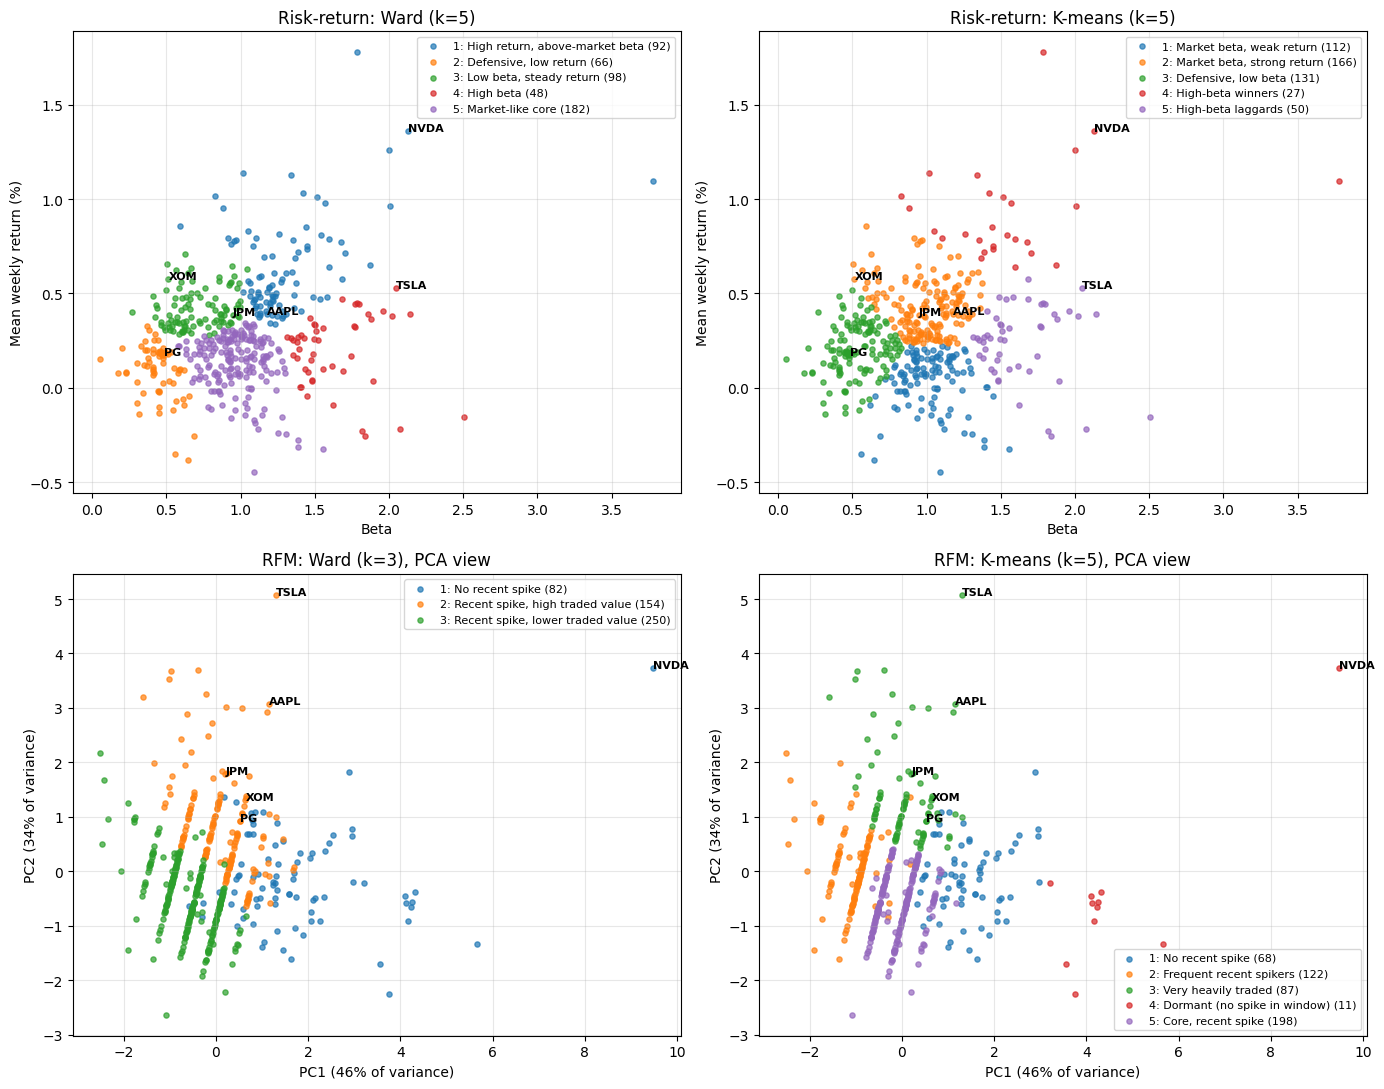

In [ ]:
# Task 2.4 - Labelled 2D cluster plots for both algorithms
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for ax, (col, title, x, y, xl, yl) in zip(axes.ravel(), panels):
    for c, name in labels[col].items():
        m = assign[col] == c
        ax.scatter(x[m], y[m], s=14, alpha=0.7, label=f"{c}: {name} ({m.sum()})")
    for t in show:
        ax.annotate(t, (x[t], y[t]), fontsize=8, fontweight="bold")
    ax.set(title=title, xlabel=xl, ylabel=yl)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("task2_cluster_plots.png", dpi=150)
plt.show()

In [ ]:
# Task 2.4 - Ward vs K-means on the same 486 shares: adjusted Rand index and crosstab
from sklearn.metrics import adjusted_rand_score
for m in ["RR", "RFM"]:
    w, k = assign[f"Ward_{m}"], assign[f"KM_{m}"]
    print(f"\n{m}: adjusted Rand index (Ward vs K-means) = {adjusted_rand_score(w, k):.3f}")
    display(pd.crosstab(w, k, rownames=[f"Ward {m}"], colnames=[f"K-means {m}"], margins=True))


RR: adjusted Rand index (Ward vs K-means) = 0.318


K-means RR,1,2,3,4,5,All
Ward RR,,,,,,
1,0,60,0,27,5,92
2,5,0,61,0,0,66
3,0,57,41,0,0,98
4,3,0,0,0,45,48
5,104,49,29,0,0,182
All,112,166,131,27,50,486



RFM: adjusted Rand index (Ward vs K-means) = 0.367


K-means RFM,1,2,3,4,5,All
Ward RFM,,,,,,
1,62,4,3,11,2,82
2,6,14,84,0,50,154
3,0,104,0,0,146,250
All,68,122,87,11,198,486


In [ ]:
# Task 2.4 - Same-k check: Ward vs K-means with equal numbers of clusters
km_rfm3 = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(Z_rfm).labels_
print(f"RFM, Ward k=3 vs K-means k=3: ARI = {adjusted_rand_score(ward_rfm, km_rfm3):.3f}")
print(f"Risk-return, Ward k=5 vs K-means k=5: ARI = {adjusted_rand_score(ward_rr, km_rr):.3f}")

RFM, Ward k=3 vs K-means k=3: ARI = 0.822
Risk-return, Ward k=5 vs K-means k=5: ARI = 0.318


In [ ]:
# Task 2.4 - Matched shares: the same six shares under both algorithms
matched = assign.loc[show].copy()
for col in matched:
    matched[col] = matched[col].map(labels[col])
matched

,Ward_RR,Ward_RFM,KM_RR,KM_RFM
Ticker,,,,
NVDA,"High return, above-market beta",No recent spike,High-beta winners,Dormant (no spike in window)
AAPL,"High return, above-market beta","Recent spike, high traded value","Market beta, strong return",Very heavily traded
TSLA,High beta,"Recent spike, high traded value",High-beta laggards,Very heavily traded
JPM,"Low beta, steady return","Recent spike, high traded value","Market beta, strong return",Very heavily traded
PG,"Defensive, low return","Recent spike, high traded value","Defensive, low beta",Very heavily traded
XOM,"Low beta, steady return","Recent spike, high traded value","Market beta, strong return",Very heavily traded


In [ ]:
# Task 2.5.1 - R, F and log1p(M) on the common share set, and their correlations
corr_df = pd.DataFrame({
    "Recency": features.loc[common, "Recency"].astype(float),
    "Frequency": features.loc[common, "Frequency"].astype(float),
    "log1p(Monetary)": np.log1p(features.loc[common, "Monetary"].astype(float))})
pearson = corr_df.corr(method="pearson").round(3)
spearman = corr_df.corr(method="spearman").round(3)

In [ ]:
# Task 2.5.1 - Pearson and Spearman correlation tables
print("Pearson correlation")
display(pearson)
print("Spearman rank correlation")
display(spearman)

Pearson correlation


,Recency,Frequency,log1p(Monetary)
Recency,1.000,-0.346,0.152
Frequency,-0.346,1.000,0.013
log1p(Monetary),0.152,0.013,1.000


Spearman rank correlation


,Recency,Frequency,log1p(Monetary)
Recency,1.000,-0.196,0.137
Frequency,-0.196,1.000,-0.048
log1p(Monetary),0.137,-0.048,1.000


In [ ]:
# Task 2.5.2 - Ward on R and F only (Monetary removed, standardised afresh, same k=3)
X_rf = features.loc[common, ["Recency", "Frequency"]].astype(float)
Z_rf = pd.DataFrame(StandardScaler().fit_transform(X_rf), index=X_rf.index, columns=X_rf.columns)
L_rf = linkage(Z_rf.values, method="ward", metric="euclidean")
ward_rf = pd.Series(fcluster(L_rf, K_WARD_RFM, criterion="maxclust"), index=Z_rf.index, name="Ward_RF")
old = ward_rfm.reindex(ward_rf.index)

In [ ]:
# Task 2.5.2 - Membership comparison: adjusted Rand index and crosstab
print("Check - mean:", Z_rf.mean().round(3).tolist(), " std:", Z_rf.std(ddof=0).round(3).tolist())
print("Cluster sizes (R+F only):", ward_rf.value_counts().sort_index().to_dict())
print(f"Adjusted Rand index, R+F+M vs R+F only: {adjusted_rand_score(old, ward_rf):.3f}")
pd.crosstab(old, ward_rf, rownames=["Ward R+F+M"], colnames=["Ward R+F only"], margins=True)

Check - mean: [-0.0, -0.0]  std: [1.0, 1.0]
Cluster sizes (R+F only): {1: 89, 2: 125, 3: 272}
Adjusted Rand index, R+F+M vs R+F only: 0.291


Ward R+F only,1,2,3,All
Ward R+F+M,,,,
1,79,0,3,82
2,9,59,86,154
3,1,66,183,250
All,89,125,272,486


In [ ]:
# Task 2.5.2 - Traded value profile function (R, F and M per cluster, M in $bn)
def m_profile(s, title):
    df = features.loc[s.index, ["Recency", "Frequency", "Monetary"]].astype(float)
    df["Monetary"] /= 1e9
    out = df.groupby(s).agg(Shares=("Recency", "size"),
                            R_median=("Recency", "median"),
                            F_median=("Frequency", "median"),
                            M_median_bn=("Monetary", "median"),
                            M_min_bn=("Monetary", "min"),
                            M_max_bn=("Monetary", "max")).round(2)
    print(f"\n{title}")
    display(out)

In [ ]:
# Task 2.5.2 - Traded value profiles: with and without Monetary
m_profile(old, "Ward with R, F and M (k=3)")
m_profile(ward_rf, "Ward with R and F only (k=3)")


Ward with R, F and M (k=3)


,Shares,R_median,F_median,M_median_bn,M_min_bn,M_max_bn
Ward_RFM,,,,,,
1,82,54.5,2.0,17.85,4.37,1825.34
2,154,11.0,3.0,39.70,18.75,1847.70
3,250,11.0,3.0,11.18,1.30,37.90



Ward with R and F only (k=3)


,Shares,R_median,F_median,M_median_bn,M_min_bn,M_max_bn
Ward_RF,,,,,,
1,89,54.0,2.0,20.85,4.37,1825.34
2,125,11.0,2.0,17.70,3.69,623.30
3,272,11.0,4.0,14.86,1.30,1847.70


# Task 3 Business Intelligence and Critical Review

In [ ]:
# Task 3.2.1 - Sector composition of each cluster solution (% of each cluster's shares)
sector = sp500_df.set_index("Ticker")["GICS Sector"].reindex(assign.index)
for col in ["Ward_RR", "KM_RR", "Ward_RFM", "KM_RFM"]:
    tab = pd.crosstab(sector, assign[col].map(labels[col]), normalize="columns").mul(100).round(0)
    print(f"\n{col} - sector mix (% of each cluster)")
    display(tab)


Ward_RR - sector mix (% of each cluster)


Ward_RR,"Defensive, low return",High beta,"High return, above-market beta","Low beta, steady return",Market-like core
GICS Sector,,,,,
Communication Services,5.0,0.0,5.0,5.0,4.0
Consumer Discretionary,0.0,21.0,12.0,9.0,9.0
Consumer Staples,33.0,0.0,0.0,5.0,3.0
Energy,0.0,0.0,4.0,16.0,0.0
Financials,3.0,10.0,14.0,29.0,14.0
Health Care,29.0,8.0,2.0,8.0,14.0
Industrials,3.0,8.0,23.0,11.0,22.0
Information Technology,0.0,48.0,32.0,2.0,11.0
Materials,2.0,4.0,3.0,3.0,8.0



KM_RR - sector mix (% of each cluster)


KM_RR,"Defensive, low beta",High-beta laggards,High-beta winners,"Market beta, strong return","Market beta, weak return"
GICS Sector,,,,,
Communication Services,5.0,2.0,0.0,5.0,4.0
Consumer Discretionary,2.0,20.0,11.0,12.0,10.0
Consumer Staples,19.0,0.0,0.0,1.0,4.0
Energy,1.0,0.0,7.0,10.0,0.0
Financials,13.0,10.0,15.0,22.0,10.0
Health Care,18.0,2.0,0.0,5.0,22.0
Industrials,9.0,8.0,22.0,20.0,20.0
Information Technology,2.0,54.0,37.0,13.0,11.0
Materials,5.0,4.0,4.0,3.0,7.0



Ward_RFM - sector mix (% of each cluster)


Ward_RFM,No recent spike,"Recent spike, high traded value","Recent spike, lower traded value"
GICS Sector,,,
Communication Services,5.0,6.0,3.0
Consumer Discretionary,11.0,13.0,7.0
Consumer Staples,9.0,7.0,6.0
Energy,2.0,6.0,3.0
Financials,12.0,16.0,16.0
Health Care,11.0,14.0,11.0
Industrials,7.0,14.0,20.0
Information Technology,22.0,20.0,10.0
Materials,10.0,1.0,5.0



KM_RFM - sector mix (% of each cluster)


KM_RFM,"Core, recent spike",Dormant (no spike in window),Frequent recent spikers,No recent spike,Very heavily traded
GICS Sector,,,,,
Communication Services,2.0,0.0,5.0,3.0,9.0
Consumer Discretionary,10.0,9.0,7.0,13.0,10.0
Consumer Staples,7.0,18.0,6.0,4.0,8.0
Energy,7.0,0.0,1.0,3.0,5.0
Financials,16.0,9.0,16.0,15.0,15.0
Health Care,9.0,18.0,16.0,10.0,15.0
Industrials,20.0,0.0,20.0,10.0,8.0
Information Technology,10.0,9.0,10.0,25.0,28.0
Materials,6.0,18.0,4.0,6.0,1.0


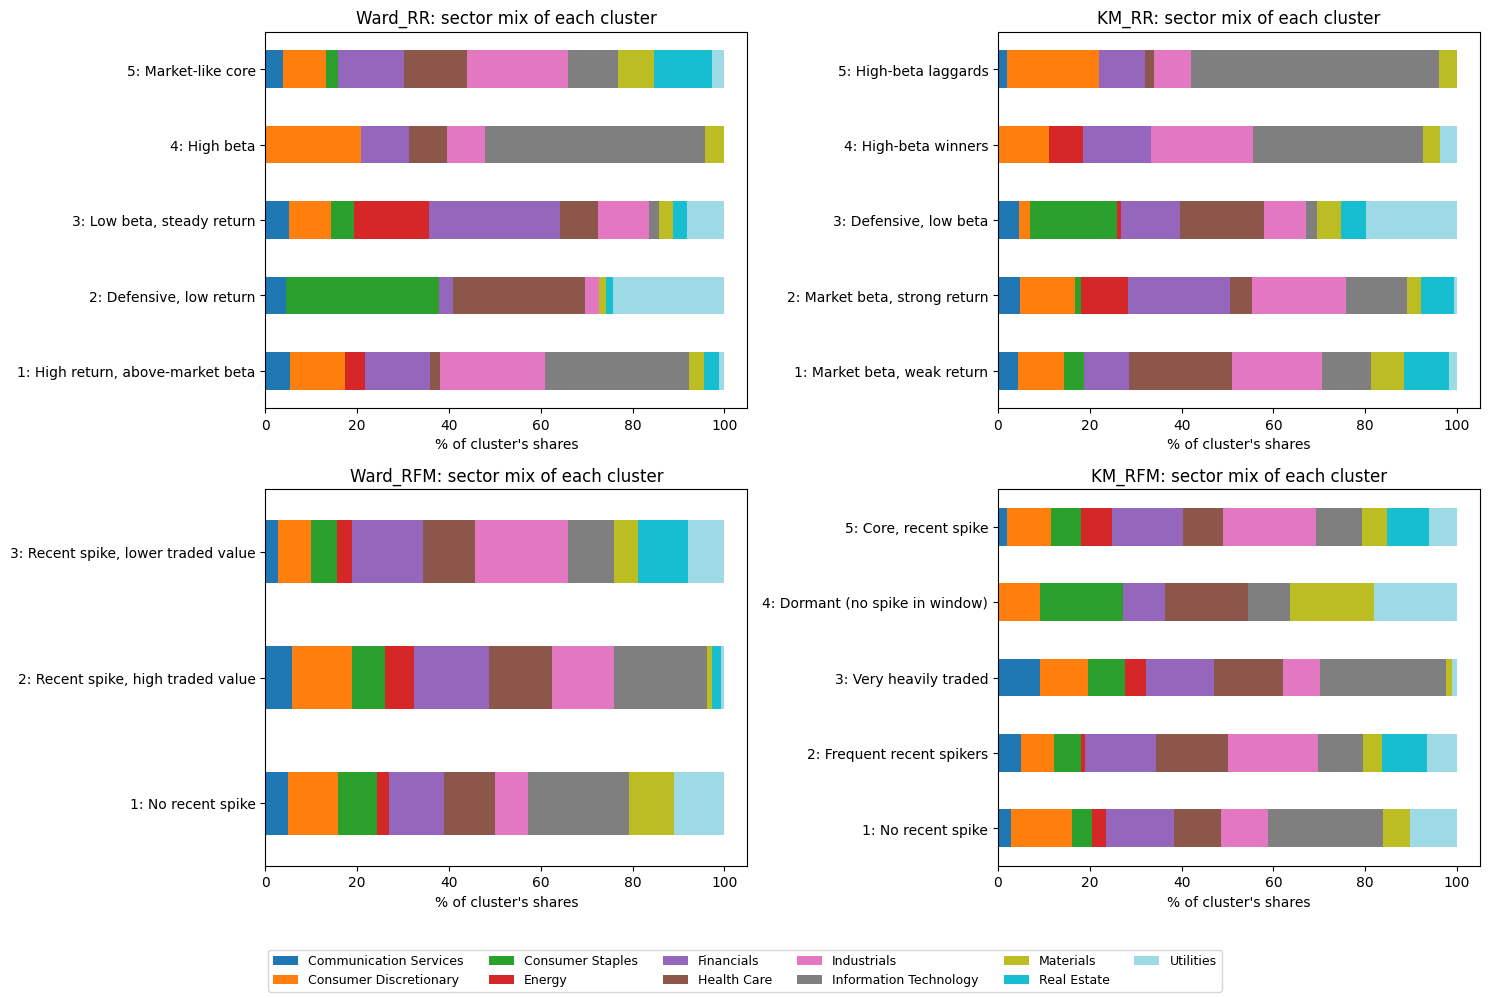

In [ ]:
# Task 3.2.1 - Sector composition chart (stacked bars)
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, col in zip(axes.ravel(), ["Ward_RR", "KM_RR", "Ward_RFM", "KM_RFM"]):
    tab = pd.crosstab(assign[col].map(lambda c: f"{c}: {labels[col][c]}"), sector, normalize="index").mul(100)
    tab.plot(kind="barh", stacked=True, ax=ax, legend=False, colormap="tab20")
    ax.set(title=f"{col}: sector mix of each cluster", xlabel="% of cluster's shares", ylabel="")
handles, names = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, names, loc="lower center", ncol=6, fontsize=9)
plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.savefig("task3_sector_composition.png", dpi=150)
plt.show()

In [ ]:
# Task 3.2.1 - Risk-return clusters vs RFM clusters on the same shares (Ward)
print(f"ARI, Ward risk-return vs Ward RFM: {adjusted_rand_score(ward_rr, ward_rfm):.3f}")
pd.crosstab(ward_rr.map(labels["Ward_RR"]), ward_rfm.map(labels["Ward_RFM"]), margins=True)

ARI, Ward risk-return vs Ward RFM: 0.039


Ward_RFM,No recent spike,"Recent spike, high traded value","Recent spike, lower traded value",All
Ward_RR,,,,
"Defensive, low return",16,23,27,66
High beta,9,20,19,48
"High return, above-market beta",19,37,36,92
"Low beta, steady return",10,35,53,98
Market-like core,28,39,115,182
All,82,154,250,486


In [ ]:
# Task 3.2.3 - Return dependencies: average correlation of weekly returns within each risk-return cluster
corr_all = share_weekly[common].corr()

def avg_corr(names):
    c = corr_all.loc[names, names].values
    return c[np.triu_indices_from(c, k=1)].mean()

rows = [{"Cluster": labels["Ward_RR"][c], "Shares": int((ward_rr == c).sum()),
         "Avg pairwise correlation": round(avg_corr(ward_rr.index[ward_rr == c]), 2)}
        for c in sorted(ward_rr.unique())]
rows.append({"Cluster": "All 486 shares", "Shares": len(common),
             "Avg pairwise correlation": round(avg_corr(common), 2)})
pd.DataFrame(rows)

,Cluster,Shares,Avg pairwise correlation
0,"High return, above-market beta",92,0.37
1,"Defensive, low return",66,0.31
2,"Low beta, steady return",98,0.32
3,High beta,48,0.44
4,Market-like core,182,0.37
5,All 486 shares,486,0.30


In [ ]:
# Final output - feature table with sector and all four cluster assignments
final = features.loc[assign.index, cols].join(sector.rename("Sector")).join(assign)
final.to_csv("final_feature_table_with_clusters.csv")
print(final.shape)
final.head()

(486, 10)


,MeanWeeklyReturn,Beta,Recency,Frequency,Monetary,Sector,Ward_RR,Ward_RFM,KM_RR,KM_RFM
Ticker,,,,,,,,,,
MMM,0.001142,0.869079,11,4,2.599146e+10,Industrials,5,2,1,2
AOS,0.001991,1.042804,11,2,4.748980e+09,Industrials,5,3,1,5
ABT,0.000971,0.583543,11,1,3.523027e+10,Health Care,2,2,3,5
ABBV,0.003749,0.425366,11,3,6.837054e+10,Health Care,3,2,3,3
ACN,0.002376,1.143301,11,2,5.199430e+10,Information Technology,5,2,2,3
